# Step 3 — Detrending (flattening) a light curve, explained

A transit search looks for a dip of a few thousand ppm (parts per million) that
lasts an hour or two and repeats. The raw light curve of an M dwarf is nothing
like a flat line with dips in it: the star brightens and fades by percent as
spots rotate in and out of view, it flares, and the telescope adds its own
drifts on top. **Detrending** (or *flattening*) is the step that removes
everything slow and keeps everything transit-like, so that the search algorithm
sees a flat line at 1.0 with the transits still in it.

This notebook explains *what* has to be done, *why*, and *how*, on a handful of
real TESS light curves from sector 104 that are already on disk. It does not run
on a whole sector; every cell works on one to five stars.

Where this step sits:

| step | what | input | output |
|---|---|---|---|
| 1 | build the target list | TESS Input Catalog | one row per star (`tic_id`, radius, mass, ...) |
| 2 | download light curves | MAST archive | one raw FITS file per star |
| **3** | **detrend** | **raw FITS** | **one flat light curve per star + one summary row per star** |
| 4 | transit search (TLS) | flat light curves | best periodic signal per star |
| 5 | vetting | search results | candidates |

Sections:

1. The problem: what is in a light curve, and why transits survive detrending at all (timescales)
2. Reading a raw light curve: flux columns, quality flags, NaNs
3. Normalising
4. Removing flares — one-sided, robust sigma clipping (and the MAD)
5. Detrending methods: sliding means, medians and the **biweight**; what **wotan** is
6. Experiment: inject fake transits and compare methods
7. Choosing the window length
8. Gaps and orbit edges
9. Error bars when the file has none
10. Putting it together on five stars, including a known planet
11. Recipe and pitfalls

In [1]:
import glob
import os
import warnings
from pathlib import Path

import dotenv
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wotan
from astropy.io import fits

dotenv.load_dotenv(Path("..") / ".env")
DATA_DIR = Path("..") / "data"
RAW_DIR = DATA_DIR / "lc_raw"

warnings.filterwarnings("ignore", module="lightkurve")
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["figure.dpi"] = 110


def raw_file(tic_id: int) -> str:
    """Path of the downloaded light-curve FITS file of one star (TESS file names zero-pad the TIC ID to 16 digits)."""
    hits = glob.glob(str(RAW_DIR / "**" / f"*{tic_id:016d}*.fits"), recursive=True)
    if not hits:
        raise FileNotFoundError(f"no raw light curve for TIC {tic_id} under {RAW_DIR}")
    return hits[0]


# The stars used in this notebook (all in sector 104, all M dwarfs)
SPOTTED = 142206123  # fast rotator: ±5 % spot modulation with a 1.6-day period, plus flares (SPOC 2-min)
MODERATE = 123519327  # slower, ~2 % variability over days, a few flares (SPOC 2-min): the "typical" case
FLARE = 140045538  # quiet star with many flares (SPOC 2-min)
QLP_EDGE = 6283622  # QLP 200-s light curve with a strong ramp at the start of each orbit
LHS3844 = 410153553  # LHS 3844: a known transiting planet, P = 0.4629 d (SPOC 2-min)
for tic in (SPOTTED, MODERATE, FLARE, QLP_EDGE, LHS3844):
    print(tic, Path(raw_file(tic)).name)

142206123 tess2026137223500-s0104-0000000142206123-0306-s_lc.fits
123519327 tess2026137223500-s0104-0000000123519327-0306-s_lc.fits
140045538 tess2026137223500-s0104-0000000140045538-0306-s_lc.fits
6283622 hlsp_qlp_tess_ffi_s0104-0000000006283622_tess_v01_llc.fits


410153553 tess2026137223500-s0104-0000000410153553-0306-s_lc.fits


## 1. The problem

### 1.1 What a light curve contains

Write the measured flux of a star as a product of independent effects:

$$
F(t) \;=\; F_0 \cdot S(t) \cdot I(t) \cdot \Big(1 - \delta\,\Pi(t)\Big) \;+\; \varepsilon(t)
$$

- $F_0$ — the mean brightness of the star (arbitrary units, electrons per second).
- $S(t)$ — **stellar variability**: starspots rotating with the star (M dwarfs rotate in 0.1 to >100 days, amplitude up to several %), flares (minutes, upward spikes of up to tens of %), pulsations (rare in M dwarfs).
- $I(t)$ — **instrumental systematics**: scattered light from the Earth and Moon, pointing jitter, thermal drifts, the "momentum dumps" when the spacecraft unloads its reaction wheels. Mostly smooth over hours to days, with ramps at the start of each orbit.
- $1 - \delta\,\Pi(t)$ — the **transit**: $\Pi(t)$ is 1 during a transit and 0 otherwise (with soft edges), $\delta = (R_p/R_\star)^2$ is the depth.
- $\varepsilon(t)$ — white noise (photon noise, read noise), roughly Gaussian.

Detrending means estimating the slow part $T(t) = F_0\,S(t)\,I(t)$ — the **trend** —
and dividing it out:

$$
\text{flat}(t) = \frac{F(t)}{T(t)} \approx 1 - \delta\,\Pi(t) + \text{noise}.
$$

Division (not subtraction) because the effects multiply: a 3 000 ppm transit on a
star that is currently 4 % brighter blocks 3 000 ppm of the *current* light.

The only reason this can work is that **the trend and the transit live on
different timescales**. If we know how long a transit lasts, we can build a
filter that follows anything slower than that and ignores anything as short as
that. So the first question is: how long is a transit?

### 1.2 How long does a transit last?

For a circular orbit, a planet much smaller than its star, crossing the centre
of the disk (impact parameter $b = 0$), the transit duration is the time the
planet takes to travel one stellar diameter along its orbit:

$$
T_{14} \approx \frac{P}{\pi}\,\frac{R_\star}{a}
$$

and Kepler's third law gives the orbital radius $a$ from the period $P$ and the
stellar mass $M_\star$:

$$
a^3 = \frac{G M_\star P^2}{4\pi^2}.
$$

Combining them: $T_{14} \propto P^{1/3}\, R_\star\, M_\star^{-1/3}$. Small, dense
stars have **short** transits. A non-central transit ($b > 0$) is shorter still,
so the formula is the *maximum* duration at a given period.

In [2]:
G = 6.674e-11
R_SUN, M_SUN = 6.957e8, 1.989e30
DAY = 86400.0


def t14_hours(period_d, r_star, m_star):
    """Central-transit duration (hours) for a circular orbit; r_star, m_star in solar units."""
    P = np.asarray(period_d) * DAY
    a = (G * m_star * M_SUN * P**2 / (4 * np.pi**2)) ** (1 / 3)
    return P / np.pi * (r_star * R_SUN / a) / 3600


periods = np.array([0.5, 1, 3, 5, 10, 13])
pd.DataFrame(
    {
        "Sun-like (1.0 R☉, 1.0 M☉)": t14_hours(periods, 1.0, 1.0),
        "early M (0.6 R☉, 0.6 M☉)": t14_hours(periods, 0.6, 0.6),
        "mid M (0.3 R☉, 0.3 M☉)": t14_hours(periods, 0.3, 0.3),
        "late M (0.15 R☉, 0.12 M☉)": t14_hours(periods, 0.15, 0.12),
    },
    index=pd.Index(periods, name="period [d]"),
).round(2)

,"Sun-like (1.0 R☉, 1.0 M☉)","early M (0.6 R☉, 0.6 M☉)","mid M (0.3 R☉, 0.3 M☉)","late M (0.15 R☉, 0.12 M☉)"
period [d],,,,
0.5,1.44,1.02,0.65,0.44
1.0,1.82,1.29,0.81,0.55
3.0,2.62,1.86,1.17,0.80
5.0,3.10,2.21,1.39,0.94
10.0,3.91,2.78,1.75,1.19
13.0,4.27,3.04,1.91,1.30


Read this table as "the longest transit we have to protect". In one TESS sector
(~25 days of data) we can only find periods up to ~13 days (we need at least
two transits), and our targets are M dwarfs with $R_\star \lesssim 0.7\,R_\odot$.
So **the longest transits we care about are ~3 hours, and most are 0.5–2 hours.**

Compare that with the other timescales in the light curve:

| phenomenon | typical timescale | what the filter must do |
|---|---|---|
| spot modulation (rotation) | 0.2 – 100 days | **follow** it (remove) |
| scattered-light ramps, thermal drifts | hours – days | **follow** it (remove) |
| transit | 0.5 – 3 hours | **ignore** it (keep in the residuals) |
| flare | minutes, upward only | **ignore** it, then clip it |
| white noise | one cadence | ignore |

The filter therefore has to be a **low-pass filter with a cut-off a few times
longer than the longest transit**. Section 7 makes "a few times" precise.

## 2. Reading a raw light curve

### 2.1 What is in the file

TESS light curves are FITS files: a header with metadata (TIC ID, sector,
camera, stellar parameters) and a binary table with one row per cadence
(exposure). Two products appear in this sector's data, with different columns:

- **SPOC** (NASA's official pipeline, 2-minute cadence): `SAP_FLUX` (simple
  aperture photometry — the sum of the pixels in an aperture, background
  subtracted) and `PDCSAP_FLUX` (SAP after *Presearch Data Conditioning*, which
  removes systematics shared by many stars on the same CCD and corrects for
  light from neighbours in the aperture). Both have error columns.
- **QLP** (MIT's Quick Look Pipeline, 200-second cadence from full-frame
  images): `SAP_FLUX` and `DET_FLUX` (QLP's own detrended flux). The error
  column belongs to `DET_FLUX`; `SAP_FLUX` has **no error column**.

In [3]:
for tic in (SPOTTED, QLP_EDGE):
    with fits.open(raw_file(tic)) as h:
        hdr0, hdr1 = h[0].header, h[1].header
        print(f"TIC {tic}: ORIGIN={hdr0.get('ORIGIN')!r}  SECTOR={hdr0['SECTOR']}  CAMERA={hdr0['CAMERA']}  "
              f"TESSMAG={hdr0['TESSMAG']}  RADIUS={hdr0['RADIUS']}  TEFF={hdr0['TEFF']}")
        print("   columns:", h[1].columns.names)
        print("   rows   :", hdr1["NAXIS2"], " cadence:", round(hdr1.get("TIMEDEL", np.nan) * 86400), "s\n")

TIC 142206123: ORIGIN='NASA/Ames'  SECTOR=104  CAMERA=4  TESSMAG=7.1792202  RADIUS=0.69269401  TEFF=3788.0
   columns: ['TIME', 'TIMECORR', 'CADENCENO', 'SAP_FLUX', 'SAP_FLUX_ERR', 'SAP_BKG', 'SAP_BKG_ERR', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY', 'PSF_CENTR1', 'PSF_CENTR1_ERR', 'PSF_CENTR2', 'PSF_CENTR2_ERR', 'MOM_CENTR1', 'MOM_CENTR1_ERR', 'MOM_CENTR2', 'MOM_CENTR2_ERR', 'POS_CORR1', 'POS_CORR2']
   rows   : 19167  cadence: 120 s

TIC 6283622: ORIGIN='MIT/QLP'  SECTOR=104  CAMERA=1  TESSMAG=12.8792  RADIUS=0.330129  TEFF=3463.0
   columns: ['TIME', 'CADENCENO', 'SAP_FLUX', 'DET_FLUX', 'DET_FLUX_ERR', 'QUALITY', 'ORBITID', 'SAP_X', 'SAP_Y', 'SAP_BKG', 'SAP_BKG_ERR', 'DET_FLUX_SML', 'DET_FLUX_LAG', 'SYS_RM_FLUX']
   rows   : 11227  cadence: 200 s



**lightkurve** (the standard Python package for Kepler/TESS light curves) reads
both formats into the same `LightCurve` object with `time`, `flux`, `flux_err`
and `quality` columns. It picks one flux column as `flux`: `PDCSAP_FLUX` for
SPOC, `SAP_FLUX` for QLP. You can see which in `lc.meta["FLUX_ORIGIN"]`.

Time is in **BTJD** (Barycentric TESS Julian Date) = BJD − 2 457 000, in days.
"Barycentric" means the arrival times are corrected to the centre of mass of the
Solar System, so they do not wobble with the spacecraft's position.

In [4]:
for tic in (SPOTTED, QLP_EDGE):
    lc = lk.read(raw_file(tic))
    print(f"TIC {tic}: author={lc.meta['AUTHOR']}, flux column={lc.meta['FLUX_ORIGIN']}, "
          f"{len(lc)} cadences, NaN flux: {np.isnan(lc.flux.value).sum()}, "
          f"NaN flux_err: {np.isnan(lc.flux_err.value).sum()}")

TIC 142206123: author=SPOC, flux column=pdcsap_flux, 17261 cadences, NaN flux:  ———, NaN flux_err:  ———


TIC 6283622: author=QLP, flux column=sap_flux, 11216 cadences, NaN flux: 122, NaN flux_err: 11216


### 2.2 Quality flags

Every cadence has an integer `QUALITY` word. Each bit flags one problem:
bit 1 attitude tweak, bit 3 spacecraft in coarse point, bit 4 Earth point,
bit 6 desaturation event (momentum dump), bit 13 scattered light, etc. A
**bitmask** is the set of bits you choose to reject: a cadence is dropped when
`quality & bitmask != 0`.

lightkurve applies its `"default"` bitmask when you read or download a SPOC
file, which removes the cadences that are truly bad. QLP uses its own bit
assignments, and in recent sectors marks its bad cadences with **bit 31
(value 2³⁰ = 1 073 741 824)**, which lightkurve's TESS bitmask does not know
about. Look at what survives in the QLP file if you trust the default:

QUALITY values present: {0: 8794, 1073741824: 1275, 1073743872: 1147}
  2**30 = 1073741824 | 2**30 + 2**11 = 1073743872 (bit 31 + bit 12)


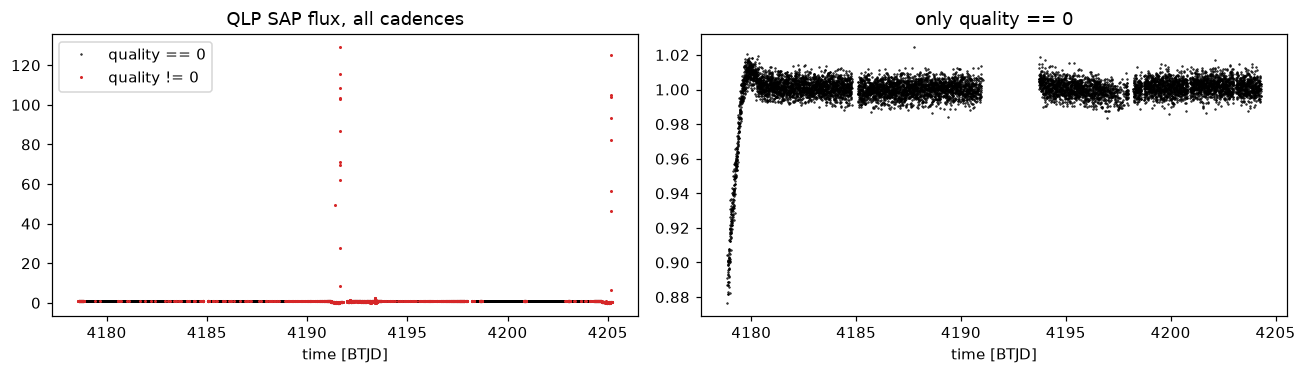

In [5]:
lc_q = lk.read(raw_file(QLP_EDGE))
q = lc_q.quality.value
vals, counts = np.unique(q, return_counts=True)
print("QUALITY values present:", dict(zip(vals.tolist(), counts.tolist())))
print("  2**30 =", 2**30, "| 2**30 + 2**11 =", 2**30 + 2**11, "(bit 31 + bit 12)")

bad = q != 0
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(lc_q.time.value[~bad], lc_q.flux.value[~bad], ".", ms=1, color="k", label="quality == 0")
axes[0].plot(lc_q.time.value[bad], lc_q.flux.value[bad], ".", ms=2, color="C3", label="quality != 0")
axes[0].set_title("QLP SAP flux, all cadences"); axes[0].legend(); axes[0].set_xlabel("time [BTJD]")
axes[1].plot(lc_q.time.value[~bad], lc_q.flux.value[~bad], ".", ms=1, color="k")
axes[1].set_title("only quality == 0"); axes[1].set_xlabel("time [BTJD]")
plt.tight_layout()

The red points include fluxes near zero and spikes ~100× the star's brightness:
no filter will make sense of those. So, for QLP, **keep only `quality == 0`**.
For SPOC, the default bitmask is the right choice (keeping only `quality == 0`
would also discard harmless flags and lose data).

After the quality cut, drop cadences whose flux is NaN (SPOC sets the flux of
some flagged cadences to NaN instead of flagging them).

## 3. Normalising

Divide the flux by its median so that the typical value is 1.0. Then every
depth and every scatter is a *fraction* — a 3 000 ppm transit is 0.003 whether
the star gives 500 or 50 000 electrons per second — and stars can be compared.
The median rather than the mean, because flares pull the mean up.

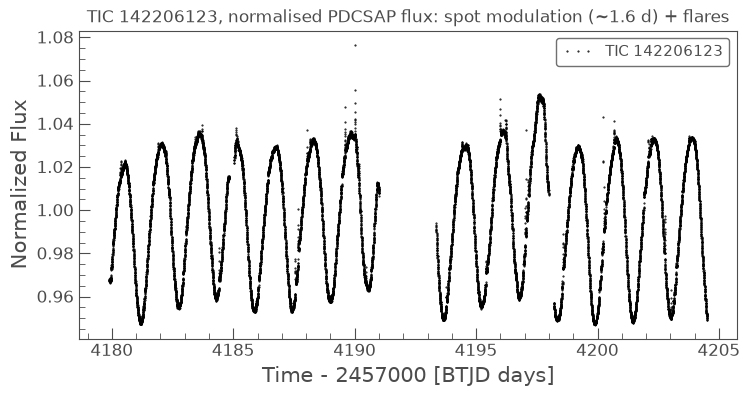

In [6]:
def read_clean(tic_id: int) -> lk.LightCurve:
    """Read one light curve, apply the right quality cut, drop NaN flux, normalise to median 1."""
    lc = lk.read(raw_file(tic_id))  # SPOC: lightkurve's "default" quality bitmask is applied here
    if str(lc.meta.get("AUTHOR", "")).upper() == "QLP":
        lc = lc[lc.quality.value == 0]  # QLP: bit 31 is unknown to lightkurve -> keep clean cadences only
    return lc.remove_nans().normalize()


lc_s = read_clean(SPOTTED)
ax = lc_s.plot(marker=".", lw=0, ms=1, color="k")
ax.set_title(f"TIC {SPOTTED}, normalised PDCSAP flux: spot modulation (~1.6 d) + flares");

This is the hard case. The spot modulation is ±5 % — **15–20 times deeper than
a typical M-dwarf transit** — and changes by several percent within a few hours.
Any transit is completely invisible in this plot.

## 4. Removing flares: one-sided robust sigma clipping

### 4.1 Why only upward

Flares are short upward spikes. They are a problem for the search (they distort
the trend, and the points right after a flare can look like a dip relative to
a trend that was pulled up). They are removed by **sigma clipping**: drop every
point more than $k\sigma$ away from the centre.

But a transit is a downward excursion. If you clip symmetrically, a deep
transit (or the in-transit points of a shallow one, on a quiet star) gets
clipped too. **Clip upward only**: `sigma_upper = 4`, `sigma_lower = ∞`.

### 4.2 Why a robust σ — the MAD and the number 1.4826

The standard deviation is itself pulled up by the flares we want to remove. A
robust alternative is the **median absolute deviation**:

$$
\text{MAD} = \operatorname{median}\big(|x_i - \operatorname{median}(x)|\big).
$$

For Gaussian noise with standard deviation σ, half of the points lie within
±0.6745σ of the centre (0.6745 is the 75th percentile of the standard normal),
so MAD = 0.6745σ, i.e.

$$
\sigma \approx \frac{\text{MAD}}{0.6745} = 1.4826 \times \text{MAD}.
$$

The factor 1.4826 turns the MAD into a standard-deviation estimate that
ignores up to 50 % contamination. You will see this number everywhere in
astronomy code.

In [7]:
rng = np.random.default_rng(42)
x = rng.normal(1.0, 0.001, 10_000)  # 1000 ppm white noise
x_flare = x.copy()
x_flare[:300] += rng.exponential(0.02, 300)  # 3 % of points are flares
for name, arr in (("clean", x), ("with 3 % flares", x_flare)):
    mad = np.median(np.abs(arr - np.median(arr)))
    print(f"{name:16s}  std = {np.std(arr)*1e6:6.0f} ppm   1.4826*MAD = {1.4826*mad*1e6:6.0f} ppm")

clean             std =   1006 ppm   1.4826*MAD =    984 ppm
with 3 % flares   std =   5162 ppm   1.4826*MAD =   1027 ppm


### 4.3 Clip before or after flattening?

On a quiet star it hardly matters. On a variable star it matters a lot: the
"centre" for the clipping is a single number for the whole light curve, and
the "σ" includes the ±5 % spot modulation, so a flare has to exceed the
*variability* to be clipped. Compare clipping the normalised flux (before
flattening) with clipping the *residuals* (after flattening, against a σ of
the noise only). We use a 0.5-day biweight flatten here; section 5 explains it.

In [8]:
def upper_clip_mask(y, k=4.0):
    """True for points to keep: drops points above median + k * robust sigma (never below)."""
    med = np.median(y)
    sigma = 1.4826 * np.median(np.abs(y - med))
    return y < med + k * sigma


rows = []
for tic in (FLARE, SPOTTED):
    lc = read_clean(tic)
    t, f = lc.time.value, lc.flux.value
    flat = wotan.flatten(t, f, method="biweight", window_length=0.5)
    keep_before = upper_clip_mask(f)
    keep_after = upper_clip_mask(flat)
    rows.append({"tic_id": tic, "points": len(f),
                 "clipped before flattening": int((~keep_before).sum()),
                 "clipped after flattening": int((~keep_after).sum())})
pd.DataFrame(rows).set_index("tic_id")

,points,clipped before flattening,clipped after flattening
tic_id,,,
140045538,15711,257,303
142206123,15662,0,243


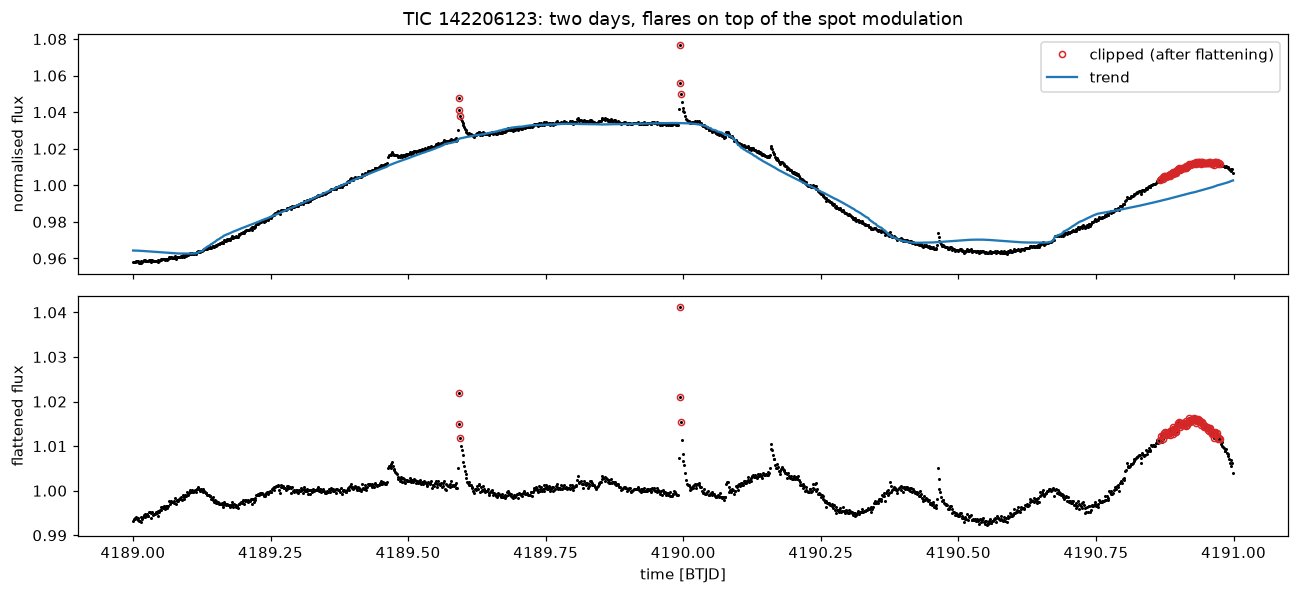

In [9]:
lc = read_clean(SPOTTED)
t, f = lc.time.value, lc.flux.value
flat, trend = wotan.flatten(t, f, method="biweight", window_length=0.5, return_trend=True)
keep_after = upper_clip_mask(flat)
win = (t > 4189) & (t < 4191)
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(t[win], f[win], ".", ms=2, color="k")
axes[0].plot(t[win & ~keep_after], f[win & ~keep_after], "o", ms=4, mfc="none", color="C3", label="clipped (after flattening)")
axes[0].plot(t[win], trend[win], "-", color="C0", label="trend")
axes[0].legend(); axes[0].set_ylabel("normalised flux")
axes[1].plot(t[win], flat[win], ".", ms=2, color="k")
axes[1].plot(t[win & ~keep_after], flat[win & ~keep_after], "o", ms=4, mfc="none", color="C3")
axes[1].set_ylabel("flattened flux"); axes[1].set_xlabel("time [BTJD]")
axes[0].set_title(f"TIC {SPOTTED}: two days, flares on top of the spot modulation");
plt.tight_layout()

On the quiet flare star both approaches find the flares. On the spotted star,
clipping *before* flattening finds almost nothing, because the 4σ threshold is
set by the spot modulation; clipping the *residuals* finds the flares.

So a good order is: **flatten with a robust filter first (it is not pulled by
flares, see §5), then clip upward outliers on the flattened flux.** Clipping
the normalised flux before flattening is still useful as a first pass against
gross outliers (cosmic rays, single bad cadences), and it is harmless — it is
just weak on variable stars.

## 5. Detrending methods — and what wotan is

### 5.1 The sliding-window idea

The simplest low-pass filter: for every cadence $t_i$, take all points within
half a window on either side, $|t_j - t_i| < w/2$, and estimate their **typical
value**. That value is the trend at $t_i$. Slide the window along.

Two design choices:

1. **Window in time, not in number of points.** TESS data have gaps; a window of
   "361 cadences" spans 12 hours in the middle of an orbit but could straddle a
   two-day gap. A window of 0.5 *days* always means 0.5 days.
2. **Which estimator of the "typical value"**. This is where methods differ, and
   where transits are either preserved or eaten.

### 5.2 Estimators: mean, median, and M-estimators

Every location estimator $\hat T$ minimises some loss over the points $x_j$ in
the window:

$$
\hat T = \arg\min_T \sum_j \rho\!\left(\frac{x_j - T}{s}\right)
$$

where $s$ is a scale (how wide the noise is) and $\rho$ is the loss function.
Its derivative $\psi = \rho'$ — the **influence function** — says how hard one
point pulls on the result:

| estimator | $\rho(u)$ | $\psi(u)$ | effect of a transit inside the window |
|---|---|---|---|
| **mean** | $u^2$ | $u$ (unbounded) | in-transit points pull the trend **down**, so the flattened transit gets **shallower**. Flares pull it up. |
| **median** | $\lvert u\rvert$ | $\operatorname{sign}(u)$ (bounded) | each point pulls with the same force no matter how far — robust, but uses only the *order* of the data, so it is noisier (≈ 64 % of the mean's statistical efficiency for Gaussian noise). |
| **Huber** | $u^2$ near 0, $\lvert u\rvert$ far | linear, then constant | compromise; outliers still pull. |
| **Tukey biweight** | see below | **returns to 0** beyond $c$ | points far from the centre have **zero** influence: the transit and the flares are simply ignored, and the inliers are averaged almost as efficiently as by the mean. |

The **Tukey biweight** ("bisquare") uses

$$
\psi(u) = u\,(1-u^2)^2 \;\text{ for } |u| < 1, \qquad \psi(u) = 0 \;\text{ otherwise},
\qquad u = \frac{x_j - T}{c \cdot \text{MAD}}.
$$

Setting $\sum_j \psi(u_j) = 0$ and writing $\psi(u) = u\,w(u)$ gives a weighted
mean with weights $w_j = (1-u_j^2)^2$ that depend on $T$ itself, so it is
solved by iteration (*iteratively reweighted mean*):

1. start from $T = \operatorname{median}(x)$ and $\text{MAD}$ of the window;
2. compute $u_j$ and weights $w_j = (1-u_j^2)^2$, set $w_j = 0$ where $|u_j| \ge 1$;
3. $T \leftarrow T + \sum_j w_j (x_j - T) / \sum_j w_j$;
4. repeat until $T$ stops changing.

The tuning constant $c$ sets where the weights reach zero. wotan uses
$c = 5$ in units of the raw MAD, i.e. $5 \times 0.6745\,\sigma \approx 3.4\,\sigma$:
any point more than ~3.4σ from the trend has no influence at all.

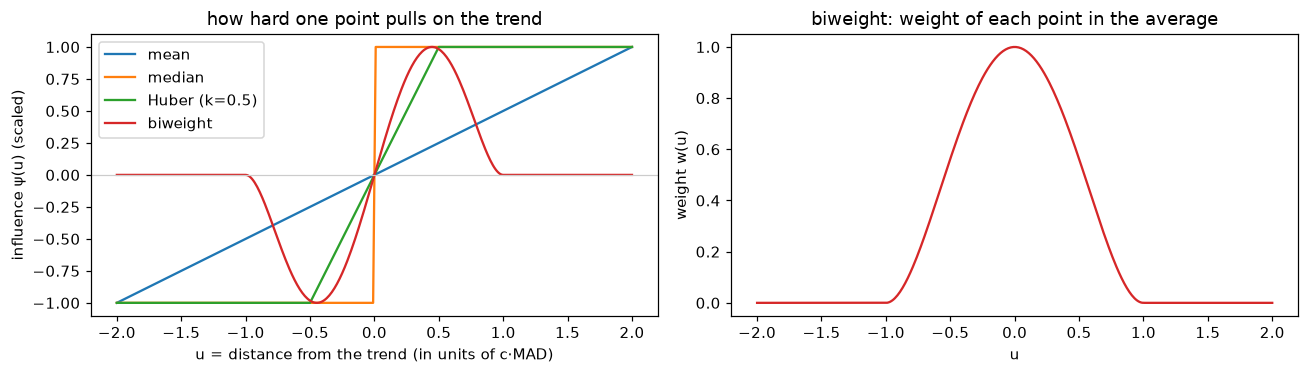

In [10]:
u = np.linspace(-2, 2, 401)
psi = {
    "mean":  u,
    "median": np.sign(u),
    "Huber (k=0.5)": np.clip(u, -0.5, 0.5),
    "biweight": np.where(np.abs(u) < 1, u * (1 - u**2) ** 2, 0.0),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, p in psi.items():
    axes[0].plot(u, p / np.max(np.abs(p)), label=name)
axes[0].set_xlabel("u = distance from the trend (in units of c·MAD)"); axes[0].set_ylabel("influence ψ(u) (scaled)")
axes[0].axhline(0, color="0.8", lw=0.8); axes[0].legend(); axes[0].set_title("how hard one point pulls on the trend")
axes[1].plot(u, np.where(np.abs(u) < 1, (1 - u**2) ** 2, 0.0), color="C3")
axes[1].set_xlabel("u"); axes[1].set_ylabel("weight w(u)"); axes[1].set_title("biweight: weight of each point in the average")
plt.tight_layout()

### 5.3 The biweight by hand, on one window

Take one 0.5-day window of noise (1 000 ppm) and put a 2-hour, 5 000 ppm
transit in it (one sixth of the window). Then compute the four estimators.
The "true" trend is 1.0.

In [11]:
def biweight_location(x, c=5.0, tol=1e-10, max_iter=100):
    """Tukey biweight location: iteratively reweighted mean starting from the median."""
    T = np.median(x)
    mad = np.median(np.abs(x - T))
    if mad == 0:
        return T
    for _ in range(max_iter):
        u = (x - T) / (c * mad)
        w = np.where(np.abs(u) < 1, (1 - u**2) ** 2, 0.0)
        step = np.sum(w * (x - T)) / np.sum(w)
        T += step
        if abs(step) < tol:
            break
    return T


rng = np.random.default_rng(1)
n = 360  # 0.5 d of 2-min cadences
window = rng.normal(1.0, 0.001, n)
window[150:210] -= 0.005  # 60 cadences = 2 h transit
print(f"{'estimator':10s} {'trend':>10s}   bias [ppm]")
for name, est in (("mean", np.mean(window)), ("median", np.median(window)), ("biweight", biweight_location(window))):
    print(f"{name:10s} {est:10.6f}   {(est - 1) * 1e6:8.0f}")

estimator       trend   bias [ppm]
mean         0.999062       -938
median       0.999688       -312
biweight     0.999864       -136


The mean is biased by ≈ (1/6) × 5 000 ≈ 830 ppm (plus noise): if this were the trend at
mid-transit, the flattened transit would be ~830 ppm shallower than it really
is. The median is biased much less, and the biweight least, because the
in-transit points sit ~5σ below the bulk and get weight zero.

The bias also tells you why the **window must be several transit durations
long**: if the transit filled half the window, even the median would lose
track (it can only ignore up to 50 % of the points).

### 5.4 Sliding it along a real light curve — and what wotan is

Sliding `biweight_location` over 15 000 cadences in pure Python works, but is
slow (each window has hundreds of points and each needs several iterations).
That is the job of **wotan**.

**wotan** (Hippke, David, Mulders & Heller 2019, *AJ* 158, 143;
arXiv:1906.00966) is a Python package that collects ~25 detrending methods
behind one function, `wotan.flatten(time, flux, method=..., window_length=...)`,
compiled with numba so the sliding filters run in milliseconds. The methods
fall into four families:

| family | `method=` | idea |
|---|---|---|
| time-windowed sliders | `mean`, `median`, `biweight`, `huber`, `welsch`, `andrewsinewave`, `trim_mean`, `winsorize`, `hodges`, `tau`, ... | a location estimator in a window of fixed *time* length (§5.1–5.3) |
| splines | `rspline` (iteratively sigma-clipped spline), `hspline` (Huber-loss spline), `pspline` (penalised) | fit a smooth piecewise polynomial; knot spacing ~ window length |
| global fits / smoothers | `cosine`, `cofiam`, `savgol`, `lowess`, `supersmoother`, `ridge`/`lasso` | sums of sines/cosines, local polynomial regression, ... |
| Gaussian processes | `gp` (with `kernel=` `squared_exp`, `matern`, `periodic`, ...) | model the variability as a correlated random process |

What made wotan the standard choice is the paper's **benchmark**: the authors
injected thousands of synthetic transits into real Kepler, K2 and TESS light
curves, detrended them with every method and window, ran a transit search, and
counted recoveries. The time-windowed **biweight** with a window of about
**three times the transit duration** came out at or near the top across all
three missions, ahead of splines, GPs and the Savitzky–Golay filter that was
the default in older tools. It is also simple (one parameter, the window) and
fast.

Two `flatten` arguments besides the method and window are worth knowing:

- `break_tolerance` (default `window_length / 2`): any gap longer than this
  splits the light curve into **segments** that are detrended independently,
  so the window never reaches across a gap.
- `edge_cutoff` (default 0): removes this many days at each segment edge
  (only for the sliding methods). More on edges in §8.
- `return_trend=True` returns `(flattened_flux, trend)` instead of only the
  flattened flux — keep the trend, it is useful for plots and diagnostics.
- `mask` (boolean array, True = in transit): masked points are excluded when
  computing the trend. Not useful for a blind search (we don't know where the
  transits are), but when re-detrending a *known* candidate before fitting it,
  masking its transits removes the residual bias completely.

Check that wotan's biweight is exactly what we wrote by hand, at a few hundred
cadences of the spotted star:

max |wotan - by hand| = 0.73 ppm


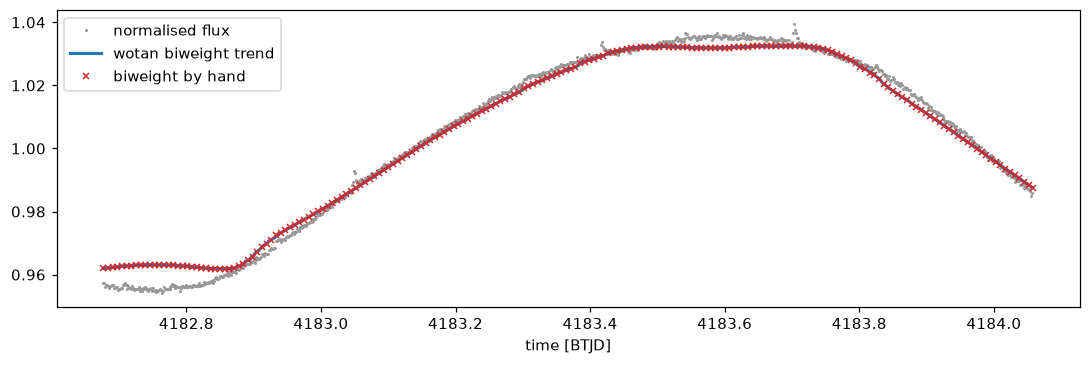

In [12]:
lc = read_clean(SPOTTED)
t, f = lc.time.value, lc.flux.value
flat_w, trend_w = wotan.flatten(t, f, method="biweight", window_length=0.5, return_trend=True)

idx = np.arange(2000, 3000, 5)  # a few hundred cadences in the middle of an orbit
trend_hand = np.array([biweight_location(f[np.abs(t - t[i]) < 0.25]) for i in idx])
print("max |wotan - by hand| =", f"{np.max(np.abs(trend_w[idx] - trend_hand)) * 1e6:.2f} ppm")

fig, ax = plt.subplots()
ax.plot(t[idx[0]:idx[-1]], f[idx[0]:idx[-1]], ".", ms=2, color="0.6", label="normalised flux")
ax.plot(t[idx[0]:idx[-1]], trend_w[idx[0]:idx[-1]], "-", color="C0", lw=2, label="wotan biweight trend")
ax.plot(t[idx], trend_hand, "x", ms=4, color="C3", label="biweight by hand")
ax.legend(); ax.set_xlabel("time [BTJD]");

## 6. Experiment: inject fake transits and compare methods

The only honest way to compare detrending methods is to put transits of
**known** depth into a **real** light curve and measure what is left after
flattening. Two numbers matter:

- **depth retention** = depth after flattening / injected depth. 1.0 is
  perfect; 0.7 means the filter ate 30 % of the transit.
- **residual scatter** = robust σ of the flattened flux *outside* transits.
  Lower is better (the search needs a flat baseline).
- **deepest fake dip** = on the light curve *without* injections, after
  clipping flares, the deepest 1.5-hour running median below 1. This is what
  the filter itself manufactures — a fake transit candidate the search will
  find.

A trick to measure retention without the star's own noise getting in the way:
flatten the light curve **twice**, once with and once without the injected
transits, using the same method. The two results are identical except for
what the filter did to the transits, so

$$
\text{retention} = \frac{\big\langle \text{flat}_{\text{without}} - \text{flat}_{\text{with}} \big\rangle_{\text{transit bottom}}}{\delta_{\text{injected}}}.
$$

We inject a train of transits into TIC 123519327, a star with ~2 % variability
over a few days and some flares — a typical active M dwarf: depth 3 000 ppm
(≈ a 1.6 R⊕ planet around a 0.3 R☉ star), duration 1.5 h, period 3.3 d. The
transit shape is a trapezoid with short ingress/egress, close enough to a real
limb-darkened transit for this purpose. Injection is multiplicative, like a
real transit.

360 in-transit points over 8 transits


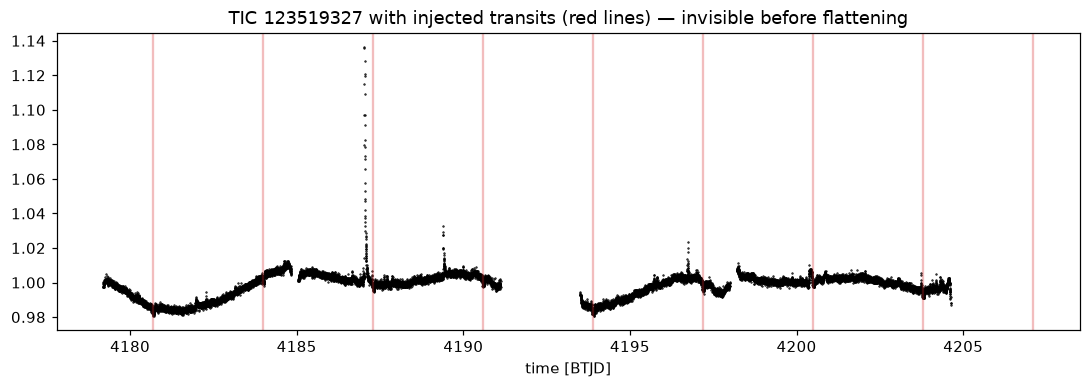

In [13]:
def trapezoid_transit(t, period, t0, duration, depth, ingress_frac=0.1):
    """Multiplicative transit model: 1 outside transit, 1 - depth at the bottom, linear ingress/egress."""
    phase = ((t - t0 + 0.5 * period) % period) - 0.5 * period  # time from nearest mid-transit, days
    x = np.abs(phase) / (duration / 2)  # 0 at centre, 1 at first/last contact
    shape = np.clip((1 - x) / ingress_frac, 0, 1)  # 1 in the flat bottom, ramps to 0 at the edges
    return 1 - depth * shape, np.abs(phase) < duration / 2


INJ = dict(period=3.3, t0=4180.7, duration=1.5 / 24, depth=3000e-6)


def inject(tic_id, inj=INJ):
    """A real star's normalised light curve, with and without fake transits."""
    lc = read_clean(tic_id)
    t, f = lc.time.value, lc.flux.value
    model, in_tr = trapezoid_transit(t, **inj)
    bottom = trapezoid_transit(t, inj["period"], inj["t0"], 0.6 * inj["duration"], inj["depth"])[1]
    epoch = np.round((t - inj["t0"]) / inj["period"]).astype(int)  # which transit each point belongs to
    return dict(t=t, f=f, f_inj=f * model, model=model, in_tr=in_tr, bottom=bottom, epoch=epoch, depth=inj["depth"])


def deepest_dip(t, flat, hours=1.5):
    """Deepest running-median dip (ppm) of a transit-like length, after clipping upward outliers (flares)."""
    keep = np.isfinite(flat) & upper_clip_mask(np.where(np.isfinite(flat), flat, 1.0))
    n = max(3, int(hours / 24 / np.median(np.diff(t))))
    return (1 - pd.Series(flat[keep]).rolling(n, center=True).median().min()) * 1e6


def score(detrend, d):
    """Flatten with and without the injected transits.

    Returns (retention, per-transit retentions, out-of-transit scatter [ppm], deepest fake dip [ppm], flat_with).
    """
    flat_without = detrend(d["t"], d["f"])
    flat_with = detrend(d["t"], d["f_inj"])
    loss = (flat_without - flat_with) / d["depth"]  # = the transit, as the filter left it, in units of the depth
    b = d["bottom"] & np.isfinite(loss)
    per_transit = pd.Series(loss[b]).groupby(d["epoch"][b]).mean()
    oot = flat_with[~d["in_tr"] & np.isfinite(flat_with)]
    scatter = 1.4826 * np.median(np.abs(oot - np.median(oot))) * 1e6
    return np.mean(loss[b]), per_transit, scatter, deepest_dip(d["t"], flat_without), flat_with


inj = inject(MODERATE)
t, f_inj = inj["t"], inj["f_inj"]
print(f"{inj['in_tr'].sum()} in-transit points over {inj['epoch'][inj['in_tr']].max() + 1} transits")
plt.plot(t, f_inj, ".", ms=1, color="k")
for k in range(9):
    plt.axvline(INJ["t0"] + k * INJ["period"], color="C3", alpha=0.3)
plt.title(f"TIC {MODERATE} with injected transits (red lines) — invisible before flattening")
plt.xlabel("time [BTJD]");

The methods compared (all with a 0.5-day window / knot spacing, i.e. the same
amount of flexibility):

- wotan `mean`, `median`, `biweight` — the sliding estimators of §5;
- wotan `rspline` — a spline re-fitted after sigma-clipping outliers, iteratively;
- wotan `hspline` — a spline fitted with the Huber loss;
- lightkurve's `flatten()` — a **Savitzky–Golay** filter (a polynomial fitted in
  a window of a fixed *number of cadences*, with iterative sigma clipping).
  0.5 d of 2-minute cadences = 361 cadences.

In [14]:
def wotan_detrender(method, window=0.5):
    return lambda t, f: wotan.flatten(t, f, method=method, window_length=window)


def savgol_detrender(window=0.5):
    def run(t, f):
        n_cad = int(window / np.median(np.diff(t))) | 1  # window in cadences, must be odd
        return lk.LightCurve(time=t, flux=f).flatten(window_length=n_cad, polyorder=2).flux.value
    return run


detrenders = {m: wotan_detrender(m) for m in ("mean", "median", "biweight", "rspline", "hspline")}
detrenders["savgol (lightkurve)"] = savgol_detrender()

summary, per_tr, flats = {}, {}, {}
for name, fn in detrenders.items():
    ret, per, scat, dip, flats[name] = score(fn, inj)
    summary[name] = {"depth retention": ret, "worst transit": per.min(), "scatter [ppm]": scat,
                     "deepest fake dip [ppm]": dip}
    per_tr[name] = per
pd.DataFrame(summary).T.astype(float).round({"depth retention": 3, "worst transit": 3, "scatter [ppm]": 0, "deepest fake dip [ppm]": 0})

,depth retention,worst transit,scatter [ppm],deepest fake dip [ppm]
mean,0.881,0.879,1226.0,8529.0
median,0.915,0.834,1172.0,2512.0
biweight,0.921,0.864,1178.0,2588.0
rspline,0.930,0.859,1368.0,6596.0
hspline,0.926,0.882,1213.0,2827.0
savgol (lightkurve),0.725,0.482,1140.0,1684.0


And transit by transit (each column is one injected transit; its mid-time is
in the header):

In [15]:
per = pd.DataFrame(per_tr).T
per.columns = [f"{INJ['t0'] + k * INJ['period']:.1f}" for k in per.columns]
per.round(2)

,4180.7,4184.0,4187.3,4190.6,4193.9,4197.2,4200.5,4203.8
mean,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88
median,0.93,0.83,0.91,0.92,0.94,0.91,0.92,0.95
biweight,0.96,0.86,0.89,0.91,0.95,0.91,0.91,0.97
rspline,0.95,0.87,0.86,0.86,0.88,1.04,0.99,0.98
hspline,0.95,0.91,0.91,0.93,0.91,0.96,0.88,0.95
savgol (lightkurve),0.77,0.79,0.82,0.80,0.76,0.82,0.55,0.48


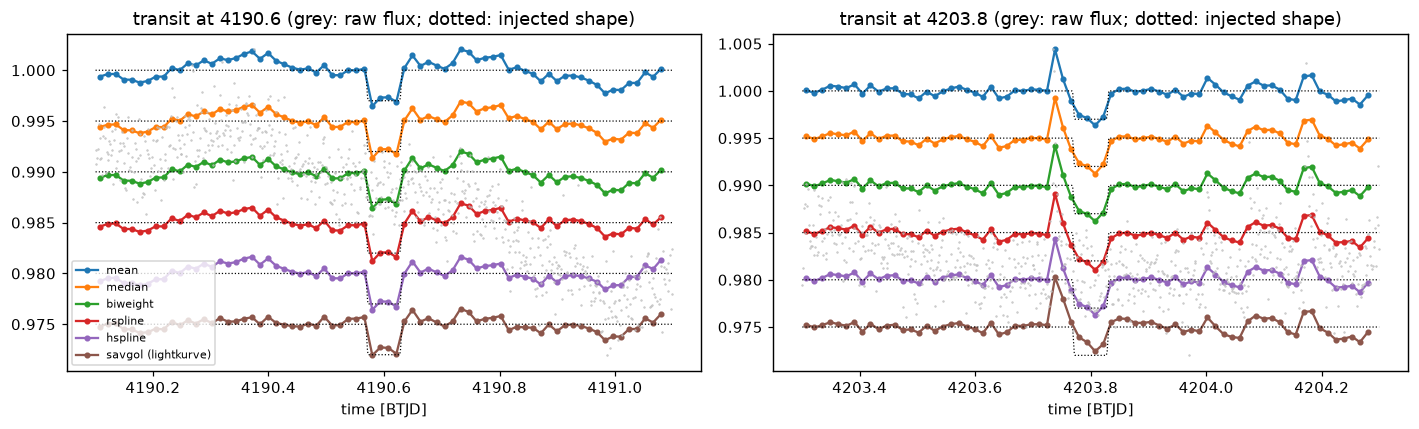

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, k in zip(axes, (3, 7)):
    i0 = INJ["t0"] + k * INJ["period"]
    zoom = np.abs(t - i0) < 0.5
    for j, (name, fl) in enumerate(flats.items()):
        tb, yb = t[zoom], fl[zoom]
        edges = np.arange(tb.min(), tb.max(), 20 / 1440)  # 20-minute bins so the dip is visible by eye
        which = np.digitize(tb, edges)
        binned = np.array([np.nanmean(yb[which == i]) for i in range(1, len(edges))])
        ax.plot(edges[:-1] + 10 / 1440, binned - 0.005 * j, "o-", ms=3, label=name)
        ax.plot(tb, inj["model"][zoom] - 0.005 * j, "k:", lw=0.8)
    ax2 = ax.twinx()
    ax2.plot(tb, inj["f"][zoom], ".", ms=1, color="0.75"); ax2.set_yticks([])
    ax.set_title(f"transit at {i0:.1f} (grey: raw flux; dotted: injected shape)")
    ax.set_xlabel("time [BTJD]")
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout()

How to read this:

- **mean**: retention 0.88 for every transit. That is exactly the bias computed
  in §5.3: the transit fills 1.5 h of a 12-h window (1/8), so the mean trend is
  pulled down by 1/8 of the depth inside the transit. The bigger problem is
  the **fake dip**: next to the big flare at BTJD ≈ 4187 the mean trend is
  pulled up for half a day, and after the flare points are removed, the
  flattened flux next to it sits ~8 000 ppm low for hours — a deeper "transit"
  than the real one. A mean filter turns every flare into a fake dip.
- **median** and **biweight**: retention 0.91–0.92, and the flare does not
  create a fake dip; their deepest fake dip (~2 500 ppm) is somewhere else, at
  the data gap at BTJD ≈ 4185 — the edge problem of §8. Note that they are *not* at 1.0: a 3 000 ppm transit on a star
  with 1 200 ppm per-point noise is only ~2.5σ below the trend, inside the
  biweight's ~3.4σ cut-off, so the in-transit points are down-weighted
  (weight ≈ 0.2) but not ignored. Robustness fully pays off for flares and
  for transits that are deep compared with the per-point noise; for transits
  buried in the noise, what protects them is the **window length** (§7).
- **rspline** (a sigma-clipped spline): fine on transits, but the flare bends
  the spline and leaves a large fake dip.
- **hspline**: close to the biweight here; slower and less used.
- **savgol (lightkurve)**: the worst at keeping depth (0.72 overall, ~0.5 near
  the end of the data, where its window is one-sided). Its fake dips are
  small because it clips flares before fitting — but it trades that against
  eating the transits.

The biweight is the best compromise here, which is also what the wotan paper
found over thousands of light curves.

## 7. Choosing the window length

The window is the one knob that matters. Too short and the filter "follows"
the transit and eats it; too long and it cannot follow the star's variability,
leaving wiggles that the search may mistake for transits. Sweep it on the
moderate star and on the fast rotator from §3:

depth retention           scatter [ppm]           fake dip [ppm]  \
tic_id           123519327 142206123     123519327 142206123      123519327   
window [d]                                                                    
0.10                  0.36      0.18       1057.79    498.50        1075.68   
0.15                  0.62      0.38       1083.23    639.39        1646.40   
0.20                  0.75      0.55       1101.84    836.16        2120.17   
0.30                  0.87      0.59       1141.56   1292.64        2417.23   
0.40                  0.91      0.59       1164.78   1880.16        2583.96   
0.50                  0.92      0.64       1178.47   2825.49        2587.65   
0.75                  0.94      0.70       1227.54   6726.63        2648.88   
1.00                  0.95      0.80       1271.19  14284.76        3216.36   
1.50                  0.97      0.96       1448.19  36987.25        5824.44   
2.00                  0.97      0.97       1692.28  48998.19        7263.01   

                      
tic_id     142206123  
window [d]            
0.10         1818.03  
0.15         3787.31  
0.20         5814.86  
0.30        10847.40  
0.40        15813.11  
0.50        19763.15  
0.75        30498.85  
1.00        41082.78  
1.50        61278.40  
2.00        66073.37

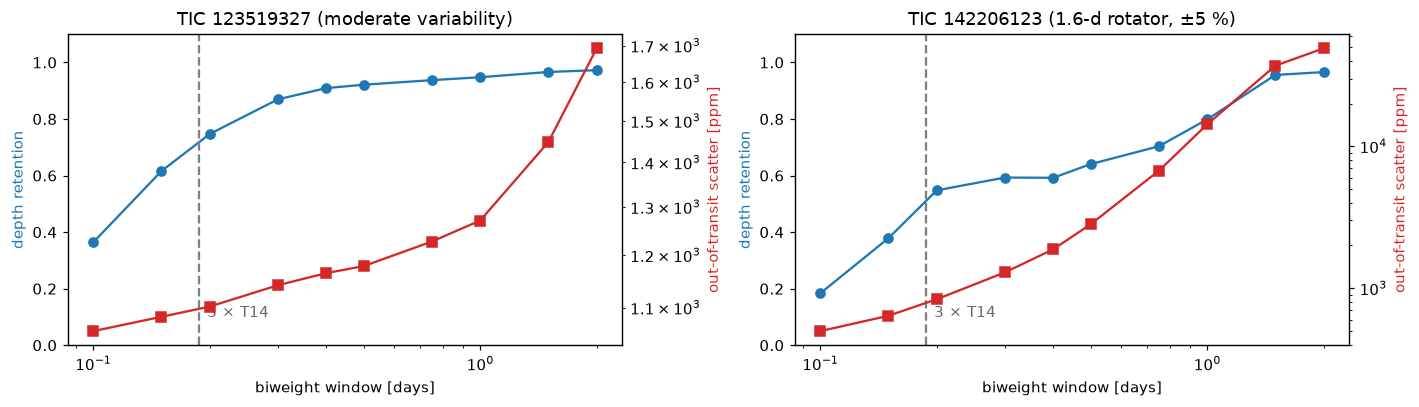

In [17]:
windows = [0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0]
sweeps = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax1, tic in zip(axes, (MODERATE, SPOTTED)):
    d = inject(tic)
    rows = [(w, *np.array(score(wotan_detrender("biweight", w), d), dtype=object)[[0, 2, 3]]) for w in windows]
    sw = pd.DataFrame(rows, columns=["window [d]", "depth retention", "scatter [ppm]", "fake dip [ppm]"]).set_index("window [d]").astype(float)
    sweeps[tic] = sw
    ax1.plot(sw.index, sw["depth retention"], "o-", color="C0")
    ax1.set_ylabel("depth retention", color="C0"); ax1.set_xscale("log"); ax1.set_xlabel("biweight window [days]")
    ax1.set_ylim(0, 1.1)
    ax2 = ax1.twinx()
    ax2.plot(sw.index, sw["scatter [ppm]"], "s-", color="C3")
    ax2.set_ylabel("out-of-transit scatter [ppm]", color="C3"); ax2.set_yscale("log")
    ax1.axvline(3 * INJ["duration"], color="0.5", ls="--")
    ax1.text(3 * INJ["duration"] * 1.05, 0.1, "3 × T14", color="0.4")
    ax1.set_title(f"TIC {tic}" + (" (moderate variability)" if tic == MODERATE else " (1.6-d rotator, ±5 %)"))
plt.tight_layout()
pd.concat(sweeps, names=["tic_id"]).unstack(0).round(2)

On the **moderate star** (left) the picture is the expected trade-off:
retention climbs steeply up to ~0.3 d and then slowly (0.92 at 0.5 d, 0.95 at
1 d); the scatter grows slowly and then fast beyond ~1 d, where the filter can
no longer follow the star. The wotan paper's rule of thumb, **window ≈ 3 × the
transit duration**, is its optimum for *detection* (depth gained vs scatter
added); here 3 × 1.5 h = 0.19 d still loses 25 % of the depth, and anything
in 0.4–0.75 d is a sensible choice.

The **fast rotator** (right) is a different regime: a ±5 % modulation with a
1.6-day period has so much curvature inside any window longer than a few
hours that the filter cannot separate it from a transit. Retention is low,
the scatter is ~10× the photon noise at 0.5 d, and the filter leaves fake
"transits" of ~2 % (the `fake dip` column). No single window works for such stars; the options are a much
shorter window (losing long transits), or modelling the rotation explicitly
(a periodic Gaussian process, or subtracting a smoothed phase-folded rotation
curve) before the short-window flatten. They are a small minority of the
targets, so a pipeline with one global window accepts reduced sensitivity for
them and flags them by their large scatter.

Now turn it around: fix the window at **0.5 days** and ask which transit
*durations* it preserves.

In [18]:
rows = []
for d_h in [0.5, 1, 1.5, 2, 3, 4, 6]:
    d = inject(MODERATE, dict(INJ, duration=d_h / 24))
    rows.append((d_h, score(wotan_detrender("biweight", 0.5), d)[0]))
pd.DataFrame(rows, columns=["T14 [h]", "retention, 0.5-d window"]).set_index("T14 [h]").round(3).T

T14 [h],0.5,1.0,1.5,2.0,3.0,4.0,6.0
"retention, 0.5-d window",0.975,0.954,0.921,0.883,0.798,0.708,0.504


With a 0.5-day (12-hour) window, transits up to ~2 hours keep ≥ 88 % of their
depth and 3-hour transits ~80 %; beyond that the loss grows quickly. From §1.2, 3 hours covers every
transit we can find in one sector around our M dwarfs. **So 0.5 days is the
right default for this target list.** Around Sun-like stars, or when searching
several sectors for long periods, you would need ~1 day or more.

## 8. Gaps and orbit edges

### 8.1 Segments

TESS observes each sector in two spacecraft orbits of ~13 days, with a gap of
~1 day in between for downloading the data, plus shorter interruptions. wotan
splits the light curve at gaps longer than `break_tolerance` and detrends each
piece separately. At both ends of every piece, the window is necessarily
**one-sided**: at the first cadence, all the points in the window are to its
right.

A one-sided window is a problem exactly where the flux changes fastest. And
the start of each orbit is where TESS has its strongest systematic: scattered
light as the spacecraft comes back from perigee makes the raw flux ramp up for
a day or so.

orbit segments start at BTJD [4178.86 4193.72]


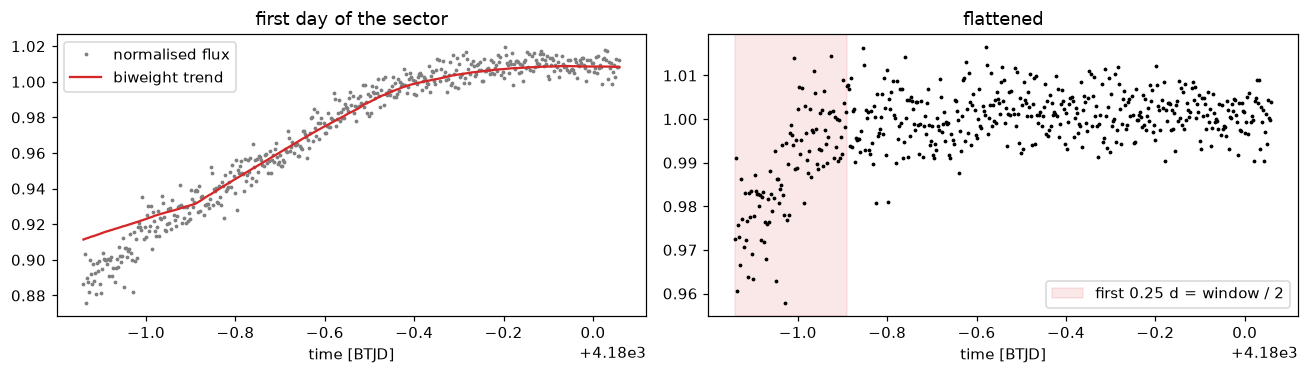

In [19]:
lc = read_clean(QLP_EDGE)
t_e, f_e = lc.time.value, lc.flux.value
flat_e, trend_e = wotan.flatten(t_e, f_e, method="biweight", window_length=0.5, return_trend=True)

gap_starts = np.r_[0, np.where(np.diff(t_e) > 0.5)[0] + 1]
print("orbit segments start at BTJD", np.round(t_e[gap_starts], 2))

first = t_e < t_e[0] + 1.2
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(t_e[first], f_e[first], ".", ms=3, color="0.5", label="normalised flux")
axes[0].plot(t_e[first], trend_e[first], "-", color="C3", label="biweight trend")
axes[0].set_title("first day of the sector"); axes[0].legend()
axes[1].plot(t_e[first], flat_e[first], ".", ms=3, color="k")
axes[1].axvspan(t_e[0], t_e[0] + 0.25, color="C3", alpha=0.1, label="first 0.25 d = window / 2")
axes[1].set_title("flattened"); axes[1].legend()
for ax in axes: ax.set_xlabel("time [BTJD]")
plt.tight_layout()

The raw flux climbs by >10 % in the first day. In the middle of the window the
biweight follows it fine; in the first quarter-day the window is one-sided,
the trend lags behind the ramp, and the flattened flux shows a **~2 % dip** —
transit-shaped, deeper than any real transit we are looking for, and right at
the start of the data. A transit search will happily report it (with the
"second transit" conveniently falling in a data gap).

### 8.2 Trim the edges — after flattening, not before

The fix: drop the first and last $w/2$ days of every orbit, which is exactly
the region where the window was one-sided. The order matters. Compare three
options by the depth of the deepest 1.7-hour dip near an orbit edge (a running
median over ~1.7 h, i.e. a transit-length average):

In [20]:
def orbit_edge_keep(time, trim, gap=0.5):
    """True for points more than `trim` days from the start/end of their orbit (segments split at gaps > `gap` d)."""
    keep = np.ones(len(time), dtype=bool)
    starts = np.r_[0, np.where(np.diff(time) > gap)[0] + 1]
    ends = np.r_[starts[1:], len(time)]
    for a, b in zip(starts, ends):
        seg = time[a:b]
        keep[a:b] = (seg - seg[0] >= trim) & (seg[-1] - seg >= trim)
    return keep


def deepest_edge_dip(time, flat, near=1.0, n_avg=31):
    """Deepest running-median dip (ppm) within `near` days of an orbit edge. n_avg=31 x 200 s ≈ 1.7 h."""
    s = pd.Series(flat).rolling(n_avg, center=True, min_periods=n_avg // 2).median().to_numpy()
    starts = np.r_[0, np.where(np.diff(time) > 0.5)[0] + 1]
    ends = np.r_[starts[1:], len(time)] - 1
    close = np.zeros(len(time), bool)
    for a, b in zip(starts, ends):
        close |= (time - time[a] < near) | (time[b] - time < near)
    return (1 - np.nanmin(s[close])) * 1e6


TRIM = 0.25
# A. no trimming
dip_a = deepest_edge_dip(t_e, flat_e)
# B. trim the raw flux first, then flatten
kb = orbit_edge_keep(t_e, TRIM)
flat_b = wotan.flatten(t_e[kb], f_e[kb], method="biweight", window_length=0.5)
dip_b = deepest_edge_dip(t_e[kb], flat_b)
# C. flatten everything, then trim
kc = orbit_edge_keep(t_e, TRIM)
dip_c = deepest_edge_dip(t_e[kc], flat_e[kc])

mid = 1.4826 * np.median(np.abs(flat_e - np.median(flat_e))) * 1e6
pd.DataFrame(
    {"deepest 1.7-h dip near an orbit edge [ppm]": [dip_a, dip_b, dip_c]},
    index=["A. no trimming", "B. trim 0.25 d, then flatten", "C. flatten, then trim 0.25 d"],
).round(0).assign(**{"(per-point noise, ppm)": round(mid)})

,deepest 1.7-h dip near an orbit edge [ppm],"(per-point noise, ppm)"
A. no trimming,25623.0,4318
"B. trim 0.25 d, then flatten",22144.0,4318
"C. flatten, then trim 0.25 d",4335.0,4318


- **A** leaves the edge artefact (~2 %).
- **B** barely helps: the ramp does not stop at 0.25 days; cutting the data
  only moves the edge to a place where the flux is *still* ramping, and the
  window is one-sided there instead.
- **C** works: the trend at 0.25 d into the orbit was computed with data on both
  sides, and the badly-estimated first 0.25 d are simply discarded.

Cost: ~4 × 0.25 d out of ~25 d, about 4 % of the data. Rule: **edge trim ≈
window / 2, applied after flattening.** If you change the window, scale the
trim.

The cleanest long-term solution is to also mask the time ranges with strong
scattered light that the TESS **Data Release Notes** list for each sector, and
the momentum-dump times. Those are known in advance and per sector, not per
star.

## 9. Error bars when the file has none

The transit search weights each point by its uncertainty `flux_err`. SPOC
provides one. QLP's `SAP_FLUX` does not (the column is NaN), so we need an
estimate. The natural one is the robust scatter of the flattened flux,
1.4826 × MAD (§4.2), the same for every point of that star.

This has a consequence for quality control. For SPOC stars, the ratio
**robust scatter of flattened flux / median `flux_err`** should be close to 1:
much larger means detrending left structure (or the star has extra
variability on transit timescales); much smaller means the pipeline's errors
are overestimated. For QLP stars that ratio is 1 **by construction**, so it
tells you nothing — use the scatter itself, compared with stars of similar
magnitude.

## 10. Putting it together

One function per star: read → quality cut → NaN removal → normalise → coarse
upward clip → flatten (biweight, 0.5 d) → trim orbit edges → upward clip on
the residuals → fill missing errors → summary numbers.

In [21]:
def detrend_star(tic_id, window_length=0.5, edge_trim=0.25, clip_sigma=4.0):
    lc = read_clean(tic_id)
    n_in = len(lc)
    # coarse upward clip against gross outliers (weak on variable stars, harmless)
    lc = lc.remove_outliers(sigma_upper=clip_sigma, sigma_lower=np.inf)
    t, f, fe = lc.time.value, lc.flux.value.astype(float), lc.flux_err.value.astype(float)

    flat, trend = wotan.flatten(t, f, method="biweight", window_length=window_length, return_trend=True)
    inside = np.isfinite(flat) & orbit_edge_keep(t, edge_trim)
    n_trimmed = int((~inside).sum())
    no_flare = upper_clip_mask(np.where(np.isfinite(flat), flat, 1.0), clip_sigma)  # flares, on the residuals
    good = inside & no_flare
    n_clipped = (n_in - len(t)) + int((inside & ~no_flare).sum())

    if not np.isfinite(fe).all():  # QLP SAP flux: no errors -> robust scatter of the flattened flux
        fe = np.full_like(f, 1.4826 * np.median(np.abs(flat[good] - np.median(flat[good]))))

    out = pd.DataFrame({"time": t[good], "flux": flat[good], "flux_err": fe[good],
                        "trend": trend[good], "flux_raw": f[good]})
    std = 1.4826 * np.median(np.abs(out.flux - out.flux.median())) * 1e6
    summary = dict(tic_id=tic_id, author=lc.meta["AUTHOR"], n_in=n_in, n_clipped=n_clipped,
                   n_trimmed=n_trimmed, n_out=len(out), std_flat_ppm=std,
                   med_err_ppm=np.median(out.flux_err) * 1e6)
    summary["std/err"] = summary["std_flat_ppm"] / summary["med_err_ppm"]
    return out, summary


stars = [SPOTTED, FLARE, QLP_EDGE, LHS3844]
outs, summ = {}, []
for tic in stars:
    outs[tic], s = detrend_star(tic)
    summ.append(s)
pd.DataFrame(summ).set_index("tic_id").round(2)

,author,n_in,n_clipped,n_trimmed,n_out,std_flat_ppm,med_err_ppm,std/err
tic_id,,,,,,,,
142206123,SPOC,15662,99,717,14846,2619.73,239.12,10.96
140045538,SPOC,15711,323,710,14678,933.08,429.36,2.17
6283622,QLP,8794,1,365,8428,4273.45,4273.45,1.00
410153553,SPOC,15896,8,718,15170,3364.52,3419.30,0.98


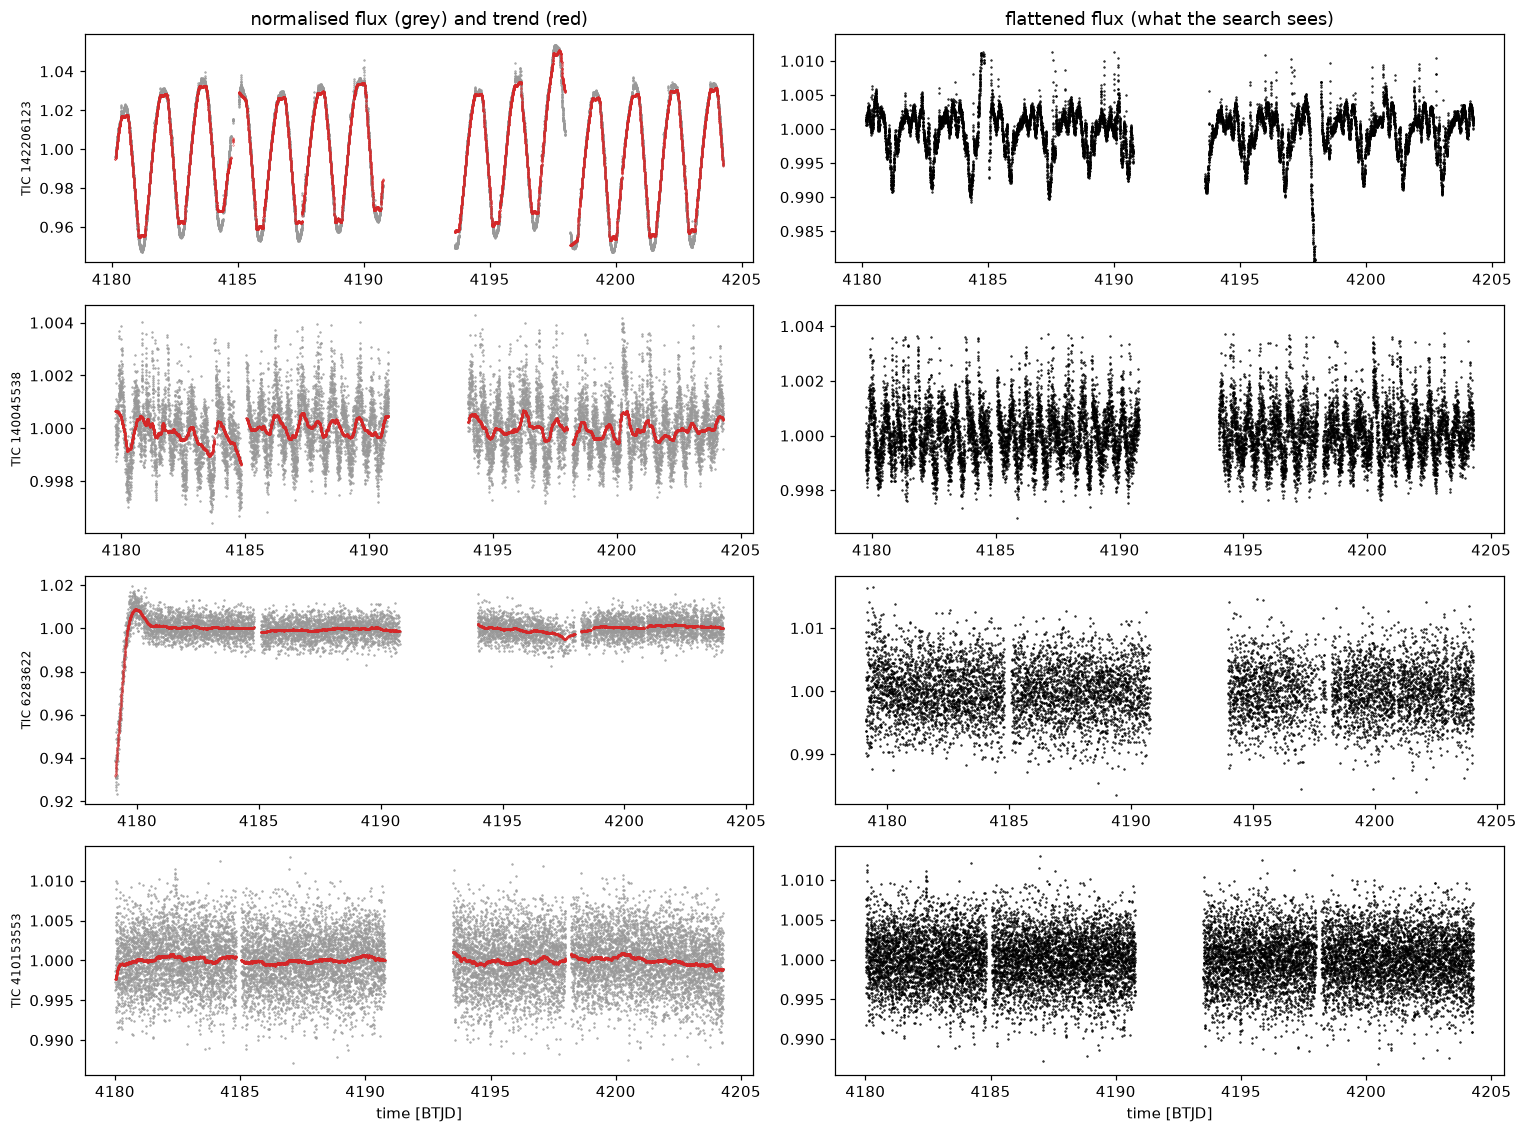

In [22]:
fig, axes = plt.subplots(len(stars), 2, figsize=(14, 2.6 * len(stars)), gridspec_kw={"width_ratios": [1, 1]})
for row, tic in zip(axes, stars):
    o = outs[tic]
    row[0].plot(o.time, o.flux_raw, ".", ms=1, color="0.6")
    row[0].plot(o.time, o.trend, ".", ms=0.5, color="C3")
    row[0].set_ylabel(f"TIC {tic}", fontsize=8)
    row[1].plot(o.time, o.flux, ".", ms=1, color="k")
    lo, hi = np.percentile(o.flux, [0.5, 99.5])
    row[1].set_ylim(lo - (hi - lo) * 0.3, hi + (hi - lo) * 0.3)
axes[0, 0].set_title("normalised flux (grey) and trend (red)")
axes[0, 1].set_title("flattened flux (what the search sees)")
for ax in axes[-1]: ax.set_xlabel("time [BTJD]")
plt.tight_layout()

Reading the summary and the plots, star by star:

- **TIC 142206123** (fast rotator): `std/err` ≈ 11 — the flattened flux still
  has dips of ~1 % at every minimum of the spot modulation (right panel). This
  is the §7 limitation, and `std/err` is the number that flags it.
- **TIC 140045538** (flare star): hundreds of flare points clipped; the
  flattened flux is clean apart from a fast low-amplitude oscillation, and
  `std/err` ≈ 2 says that oscillation is real stellar signal on transit-like
  timescales, not noise.
- **TIC 6283622** (QLP): the >5 % ramp at the start is gone after trimming
  (compare with §8). `std/err` = 1 by construction (§9).
- **LHS 3844** (SPOC): `std/err` ≈ 1, the ideal case — the flattened flux is
  white noise plus, hidden in it, ~50 transits.

### 10.1 Did the real transits survive?

LHS 3844 b (Vanderspek et al. 2019) transits every 0.46293 days, with a depth
of ~4 000–4 500 ppm and a duration of ~31 minutes. It is invisible by eye in a
single cadence (the per-point noise is about as large as the depth), but folding
~50 transits on the known period makes it obvious. We find the transit phase by
looking for the lowest phase bin, then compare the folded depth in the
flattened flux with the folded depth in the *normalised* flux before
flattening (PDCSAP flux of this star is already fairly flat, so the raw fold is
a fair reference).

flux     : depth at transit centre =  4205 ppm
flux_raw : depth at transit centre =  4216 ppm


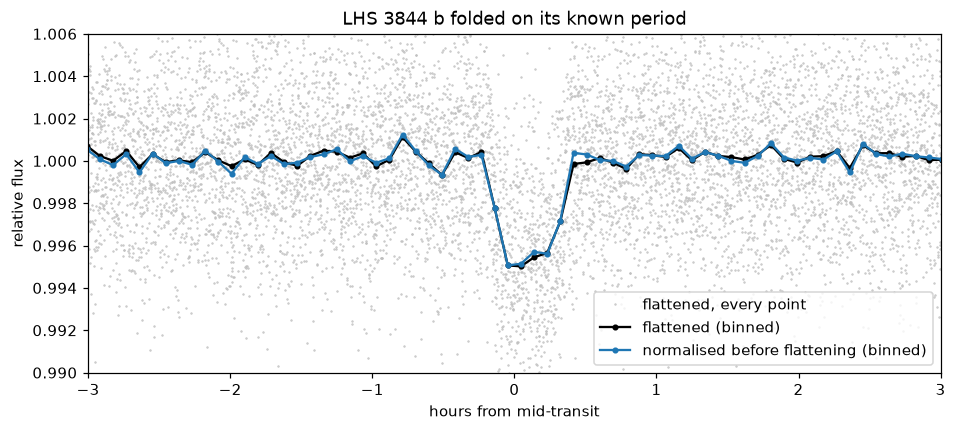

In [23]:
P_B = 0.46292913  # days
o = outs[LHS3844]
nb = 100  # phase bins of ~6.7 minutes; the transit spans ~5 of them
phase = (o.time.values % P_B) / P_B
which = np.digitize(phase, np.linspace(0, 1, nb + 1)) - 1
fold_flat = np.array([np.mean(o.flux.values[which == j]) for j in range(nb)])
j0 = np.argmin(fold_flat)  # the lowest bin is the transit
phase_c = ((phase - (j0 + 0.5) / nb + 0.5) % 1) - 0.5  # transit at phase 0

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(phase_c * P_B * 24, o.flux, ".", ms=1, color="0.75", label="flattened, every point")
for col, color, lab in (("flux", "k", "flattened (binned)"), ("flux_raw", "C0", "normalised before flattening (binned)")):
    y = o[col].values / np.median(o[col].values)
    b = np.linspace(-0.5, 0.5, 121)
    w = np.digitize(phase_c, b) - 1
    yb = np.array([np.median(y[w == j]) for j in range(len(b) - 1)])
    ax.plot((b[:-1] + b[1:]) / 2 * P_B * 24, yb, "o-", ms=3, color=color, label=lab)
ax.set_xlim(-3, 3); ax.set_ylim(0.99, 1.006)
ax.set_xlabel("hours from mid-transit"); ax.set_ylabel("relative flux"); ax.legend(loc="lower right")
ax.set_title("LHS 3844 b folded on its known period");

in_b = np.abs(phase_c * P_B * 24) < 0.15  # central ~20 min of the 31-min transit
for col in ("flux", "flux_raw"):
    y = o[col].values / np.median(o[col].values)
    print(f"{col:9s}: depth at transit centre = {(1 - np.mean(y[in_b])) * 1e6:5.0f} ppm")

The transit is there after flattening, with essentially the same depth as
before: a 31-minute transit is ~4 % of a 12-hour window, far below what the
biweight would react to.

## 11. Recipe and pitfalls

**Recipe** (per star, independent of every other star, so it parallelises
trivially across CPU cores):

1. Read the light curve. SPOC: lightkurve's default quality bitmask. QLP:
   keep only `quality == 0` (bit 31 marks bad cadences and is not in the
   default bitmask). Drop NaN flux. Skip the star if almost nothing is left.
2. Normalise by the median.
3. Clip **upward** outliers only (4σ, robust σ). Doing it on the flattened
   residuals as well catches flares on variable stars.
4. Flatten with wotan's **biweight**, `window_length` ≈ 3 × longest transit
   duration to preserve — **0.5 d** for M dwarfs in one sector — and keep the
   trend.
5. Drop the first and last **window / 2** days of each orbit **after**
   flattening.
6. Fill missing `flux_err` with 1.4826 × MAD of the flattened flux.
7. Save `time, flux (flattened), flux_err, trend, flux_raw` per star, and one
   summary row per star (points in / clipped / trimmed / out, robust scatter,
   median error, status) for quality control.

**Pitfalls**:

- Never clip downward — those are the transits.
- A window in **cadences** (Savitzky–Golay, `medfilt`) means a different time
  span across gaps; prefer a window in **days**.
- The mean is not robust: it shrinks transits and is pulled by flares.
- A window too short eats transits; too long leaves stellar variability that
  the search will call a planet. Check with injections (§6–7) whenever you
  change targets or the window.
- Orbit edges are the most common source of false single "transits". Trim
  them after flattening.
- For QLP, the scatter/error ratio is 1 by construction; it is a meaningful
  diagnostic only for light curves with real error bars.
- Not yet handled here: masking the scattered-light windows and momentum
  dumps listed in each sector's Data Release Notes.

**References**: Hippke et al. 2019, *wotan* (AJ 158, 143; arXiv:1906.00966);
github.com/hippke/wotan. Winn 2010, *Transits and Occultations*
(arXiv:1001.2010) for the duration formula. Vanderspek et al. 2019 for
LHS 3844 b. Lightkurve tutorials: lightkurve.github.io/lightkurve/tutorials/.